# Linear Regression on Iris Dataset

In this lab, we formulate a regression problem using the **built-in Iris dataset from scikit-learn**.
We predict continuous **Petal Length** based on **Petal Width** (Simple Linear Regression) and then extend to all other features (Multiple Linear Regression).

#### Equation:
$$\hat{y} = b_0 + b_1 X_1$$
$$\hat{y} = \theta_0 + \theta_1 X_1 + \theta_2 X_2 + \dots + \theta_n X_n = X\theta$$

### 1. Importing the necessary modules

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

### 2. Loading the built-in Iris dataset directly from scikit-learn

In [4]:
iris = load_iris(as_frame=True)
# Extract feature measurements into a DataFrame
df = iris.data
# Reorder so petal length (our regression target) is the last column
df = df[['sepal length (cm)', 'sepal width (cm)', 'petal width (cm)', 'petal length (cm)']]
df.head()
df.describe()

,sepal length (cm),sepal width (cm),petal width (cm),petal length (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,1.199333,3.758000
std,0.828066,0.435866,0.762238,1.765298
min,4.300000,2.000000,0.100000,1.000000
25%,5.100000,2.800000,0.300000,1.600000
50%,5.800000,3.000000,1.300000,4.350000
75%,6.400000,3.300000,1.800000,5.100000
max,7.900000,4.400000,2.500000,6.900000


### 3. Understanding the dataset features and target
Target variable: `petal length (cm)` (continuous output to predict)

In [5]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal width (cm)   150 non-null    float64
 3   petal length (cm)  150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


,sepal length (cm),sepal width (cm),petal width (cm),petal length (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,1.199333,3.758000
std,0.828066,0.435866,0.762238,1.765298
min,4.300000,2.000000,0.100000,1.000000
25%,5.100000,2.800000,0.300000,1.600000
50%,5.800000,3.000000,1.300000,4.350000
75%,6.400000,3.300000,1.800000,5.100000
max,7.900000,4.400000,2.500000,6.900000


In [18]:
df

,sepal length (cm),sepal width (cm),petal width (cm),petal length (cm)
0,5.1,3.5,0.2,1.4
1,4.9,3.0,0.2,1.4
2,4.7,3.2,0.2,1.3
3,4.6,3.1,0.2,1.5
4,5.0,3.6,0.2,1.4
...,...,...,...,...
145,6.7,3.0,2.3,5.2
146,6.3,2.5,1.9,5.0
147,6.5,3.0,2.0,5.2
148,6.2,3.4,2.3,5.4


### Part A: Simple Linear Regression (Petal Width -> Petal Length)
#### Slicing X (Petal Width) and y (Petal Length)

In [6]:
# Slicing feature matrix X and target vector y
X_simple = df[['petal width (cm)']].values
y_simple = df['petal length (cm)'].values
X_simple[:5], y_simple[:5]

(array([[0.2],
        [0.2],
        [0.2],
        [0.2],
        [0.2]]),
 array([1.4, 1.4, 1.3, 1.5, 1.4]))

### Splitting the Simple Regression dataset into Training and Test set

In [7]:
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_simple, y_simple, test_size=0.2, random_state=0)
print("Training set shape:", X_train_s.shape)
print("Testing set shape:", X_test_s.shape)

Training set shape: (120, 1)
Testing set shape: (30, 1)


### Training the Simple Linear Regression model

In [8]:
regressor_s = LinearRegression()
regressor_s.fit(X_train_s, y_train_s)

print(f"Intercept (b0): {regressor_s.intercept_:.4f}")
print(f"Slope (b1): {regressor_s.coef_[0]:.4f}")
print(f"Regression Line: y' = {regressor_s.intercept_:.4f} + {regressor_s.coef_[0]:.4f} * PetalWidth")

Intercept (b0): 1.0707
Slope (b1): 2.2288
Regression Line: y' = 1.0707 + 2.2288 * PetalWidth


### Predicting the Test set results

In [9]:
y_pred_s = regressor_s.predict(X_test_s)
comparison_df = pd.DataFrame({"Actual Petal Length": y_test_s, "Predicted Petal Length": y_pred_s})
comparison_df.head(10)

,Actual Petal Length,Predicted Petal Length
0,5.1,6.419851
1,4.0,3.299487
2,1.4,1.516423
3,6.3,5.082552
4,1.5,1.516423
5,6.0,6.642734
6,1.3,1.739306
7,4.7,4.413903
8,4.8,4.191020
9,4.0,3.968137


### Evaluating Simple Linear Regression

In [10]:
mse_s = mean_squared_error(y_test_s, y_pred_s)
rmse_s = np.sqrt(mse_s)
r2_s = r2_score(y_test_s, y_pred_s)

print(f"Mean Squared Error (MSE): {mse_s:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_s:.4f}")
print(f"R-squared Score (R2): {r2_s:.4f}")

Mean Squared Error (MSE): 0.3381
Root Mean Squared Error (RMSE): 0.5814
R-squared Score (R2): 0.8781


### Visualizing Simple Linear Regression results (Training vs Test set)

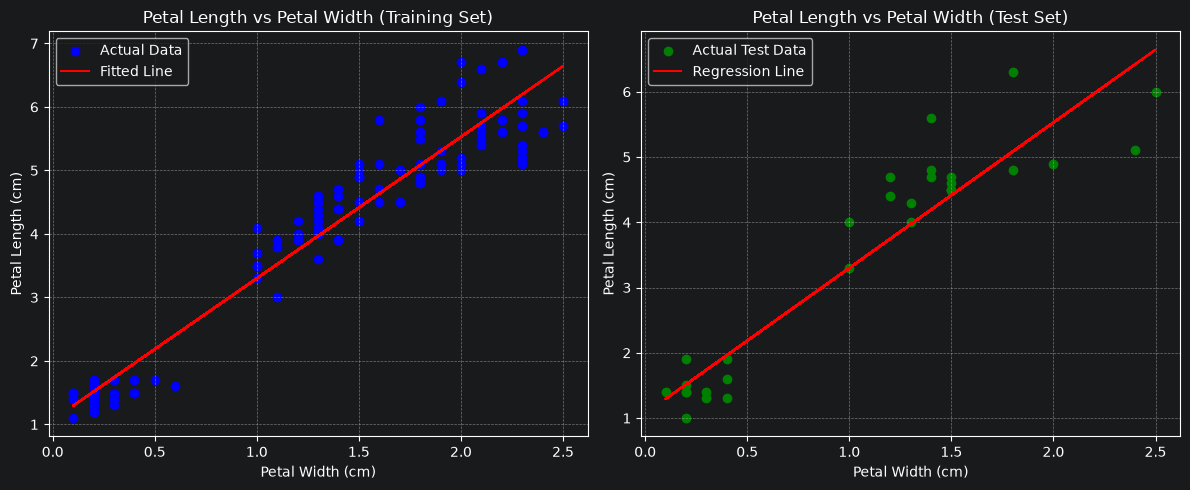

In [11]:
plt.figure(figsize=(12, 5))

# Training set results
plt.subplot(1, 2, 1)
plt.scatter(X_train_s, y_train_s, color="blue", label="Actual Data")
plt.plot(X_train_s, regressor_s.predict(X_train_s), color="red", label="Fitted Line")
plt.title("Petal Length vs Petal Width (Training Set)")
plt.xlabel("Petal Width (cm)")
plt.ylabel("Petal Length (cm)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Test set results
plt.subplot(1, 2, 2)
plt.scatter(X_test_s, y_test_s, color="green", label="Actual Test Data")
plt.plot(X_train_s, regressor_s.predict(X_train_s), color="red", label="Regression Line")
plt.title("Petal Length vs Petal Width (Test Set)")
plt.xlabel("Petal Width (cm)")
plt.ylabel("Petal Length (cm)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

---
### Part B: Multiple Linear Regression (All Features -> Petal Length)
#### Slicing X (sepal length, sepal width, petal width) and y (petal length)

In [12]:
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values
X[:5], y[:5]

(array([[5.1, 3.5, 0.2],
        [4.9, 3. , 0.2],
        [4.7, 3.2, 0.2],
        [4.6, 3.1, 0.2],
        [5. , 3.6, 0.2]]),
 array([1.4, 1.4, 1.3, 1.5, 1.4]))

### Splitting into Training and Test set

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")

X_train shape: (120, 3), y_train shape: (120,)


### Training the Multiple Linear Regression model

In [14]:
regressor = LinearRegression()
regressor.fit(X_train, y_train)

print(f"Intercept (b0): {regressor.intercept_:.4f}")
feature_names = df.columns[:-1]
for name, coef in zip(feature_names, regressor.coef_):
    print(f"Coefficient for {name}: {coef:.4f}")

Intercept (b0): -0.2653
Coefficient for sepal length (cm): 0.7006
Coefficient for sepal width (cm): -0.6104
Coefficient for petal width (cm): 1.4817


### Predicting and Evaluating Multiple Linear Regression

In [15]:
y_pred = regressor.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Multiple Regression MSE:  {mse:.4f}")
print(f"Multiple Regression RMSE: {rmse:.4f}")
print(f"Multiple Regression R2:   {r2:.4f}")

Multiple Regression MSE:  0.1352
Multiple Regression RMSE: 0.3676
Multiple Regression R2:   0.9513


---
### Part C: Syllabus Deep Dive - Normal Equation vs Gradient Descent
The syllabus specifically requires understanding the **Normal Equation** and **Gradient Descent method**:

1. **Normal Equation (Closed-form solution)**:
   $$\theta = (X^T X)^{-1} X^T y$$
   Where $X$ has an added column of 1s for the bias (intercept $\theta_0$).

In [16]:
# Add bias column (x0 = 1) to X_train
X_b = np.c_[np.ones((len(X_train), 1)), X_train]

# Compute theta using Normal Equation
theta_normal = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y_train

print("Normal Equation Parameters:")
print(f"theta_0 (Intercept): {theta_normal[0]:.4f} (sklearn intercept: {regressor.intercept_:.4f})")
for i, name in enumerate(feature_names):
    print(f"theta_{i+1} ({name}): {theta_normal[i+1]:.4f} (sklearn coef: {regressor.coef_[i]:.4f})")

Normal Equation Parameters:
theta_0 (Intercept): -0.2653 (sklearn intercept: -0.2653)
theta_1 (sepal length (cm)): 0.7006 (sklearn coef: 0.7006)
theta_2 (sepal width (cm)): -0.6104 (sklearn coef: -0.6104)
theta_3 (petal width (cm)): 1.4817 (sklearn coef: 1.4817)


2. **Batch Gradient Descent Method**:
   Cost function: $J(\theta) = \frac{1}{2m} \sum_{i=1}^m (h_\theta(x^{(i)}) - y^{(i)})^2$
   Gradient update: $\theta := \theta - \alpha \frac{1}{m} X^T (X\theta - y)$

Gradient Descent Final Parameters:
theta_0 (Intercept): -0.1263
theta_1 (sepal length (cm)): 0.7036
theta_2 (sepal width (cm)): -0.6544
theta_3 (petal width (cm)): 1.4647


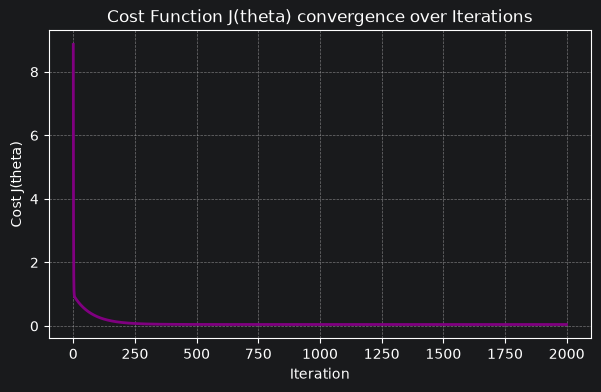

In [17]:
# Gradient Descent implementation from scratch
learning_rate = 0.01
n_iterations = 2000
m = len(X_b)

# Initialize theta with zeros
theta_gd = np.zeros(X_b.shape[1])
cost_history = []

for iteration in range(n_iterations):
    predictions = X_b @ theta_gd
    errors = predictions - y_train
    gradients = (1 / m) * (X_b.T @ errors)
    theta_gd -= learning_rate * gradients
    cost = (1 / (2 * m)) * np.sum(errors ** 2)
    cost_history.append(cost)

print("Gradient Descent Final Parameters:")
print(f"theta_0 (Intercept): {theta_gd[0]:.4f}")
for i, name in enumerate(feature_names):
    print(f"theta_{i+1} ({name}): {theta_gd[i+1]:.4f}")

# Plot Cost vs Iterations
plt.figure(figsize=(7, 4))
plt.plot(cost_history, color="purple", lw=2)
plt.title("Cost Function J(theta) convergence over Iterations")
plt.xlabel("Iteration")
plt.ylabel("Cost J(theta)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()